# Module 7 — Pathway Enrichment Analysis (GSEA)

**Biological question:** Which biological pathways are systematically up- or down-regulated in each PAM50 subtype? Individual DE genes are hard to interpret; grouping them into known pathways (gene sets) reveals the functional biology that distinguishes subtypes.

**Method:** Gene Set Enrichment Analysis (GSEA) pre-ranked:
1. For each subtype, rank all genes by a score: **−log₁₀(FDR) × sign(log₂FC)**. Genes strongly upregulated and significant get high positive scores; strongly downregulated get large negative scores.
2. Test whether each gene set (pathway) is enriched at the top (overexpressed) or bottom (underexpressed) of this ranked list — without an arbitrary significance cutoff.
3. The **Normalised Enrichment Score (NES)** summarises the direction and magnitude: NES > 1.5 with FDR < 0.25 is the standard GSEA significance threshold.

**Gene sets:** MSigDB Hallmark collection — 50 curated gene sets representing well-defined biological states (e.g. 'HALLMARK_ESTROGEN_RESPONSE_EARLY', 'HALLMARK_E2F_TARGETS'). These are concise and biologically interpretable.

> **Note:** GSEA queries the MSigDB API. If the network is unavailable, the notebook will complete with empty GSEA results and show a warning.

In [1]:
import sys
sys.path.insert(0, "..")

import logging
import matplotlib.pyplot as plt
import pandas as pd

from src.constants import InterimFile
from src.paths import interim_file
from src.data.annotation import fetch_gene_symbols
from src.features.pathway_enrichment import build_ranked_list, run_gsea_preranked

logging.basicConfig(level=logging.INFO, format="%(message)s")

## Load DE Results and Gene Annotation

In [2]:
de = pd.read_csv(interim_file(InterimFile.DE_RESULTS))
print(f"DE results: {len(de):,} rows, {de['subtype'].nunique()} subtypes")

cache = interim_file(InterimFile.GENE_ANNOTATION)
raw_ids = de["gene"].unique().tolist()
ensembl_ids = list(dict.fromkeys(eid.split(".")[0] for eid in raw_ids))

annotation = fetch_gene_symbols(ensembl_ids=ensembl_ids, cache_path=cache)
print(f"Annotation: {annotation['symbol'].notna().sum()} / {len(annotation)} IDs mapped to symbols")

Loading gene annotation from cache: gene_annotation.csv.gz


DE results: 30,000 rows, 5 subtypes
Annotation: 4499 / 5000 IDs mapped to symbols


## Basal Subtype — GSEA Against MSigDB Hallmark

In [3]:
ranked_basal = build_ranked_list(
    de_results=de,
    subtype="Basal",
    gene_symbols=annotation,
)
print(f"Ranked list (Basal): {len(ranked_basal)} genes")
print(ranked_basal.head(10).to_string())

Ranked list for Basal: 4492 genes


Ranked list (Basal): 4492 genes
symbol
BCL11A          110.005397
FOXCUT           82.238476
FOXC1            78.635483
EEF1DP5          75.881330
CDCA7            74.047989
PSAT1            71.314635
LOC101929004     70.896894
B3GNT5           69.514093
ROPN1            68.779662
BLACAT1          68.500934


In [4]:
try:
    gsea_basal = run_gsea_preranked(
        ranked=ranked_basal,
        gene_sets="MSigDB_Hallmark_2020",
    )
    print(f"GSEA (Basal): {len(gsea_basal)} gene sets tested")
except Exception as exc:
    print(f"GSEA unavailable: {exc}")
    gsea_basal = pd.DataFrame(columns=["Term", "NES", "pval", "fdr"])

2026-10-28 17:27:36,098 [WARNING] Duplicated values found in preranked stats: 0.87% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


maxp pruned


cmap pruned


kern dropped


post pruned


...

GPOS pruned


GSUB pruned


name pruned


GSEA: 28 gene sets tested


GSEA (Basal): 28 gene sets tested


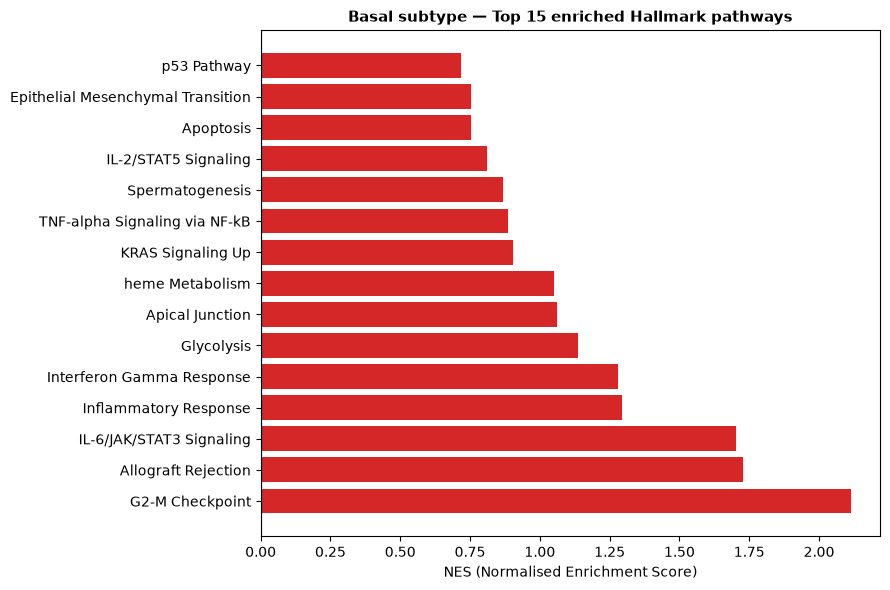

In [5]:
if not gsea_basal.empty and "NES" in gsea_basal.columns:
    top_basal = gsea_basal.nlargest(15, "NES")

    fig, ax = plt.subplots(figsize=(9, 6))
    colors = ["#d62728" if n > 0 else "#1f77b4" for n in top_basal["NES"]]
    ax.barh(top_basal["Term"], top_basal["NES"], color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("NES (Normalised Enrichment Score)")
    ax.set_title("Basal subtype — Top 15 enriched Hallmark pathways", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("No GSEA results to plot (API may be unavailable).")

## LumA Subtype — GSEA

Ranked list for LumA: 4492 genes


2026-10-28 17:27:43,862 [WARNING] Duplicated values found in preranked stats: 2.23% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


maxp pruned


cmap pruned


kern dropped


...

GDEF pruned


GPOS pruned


GSUB pruned


name pruned


GSEA: 28 gene sets tested


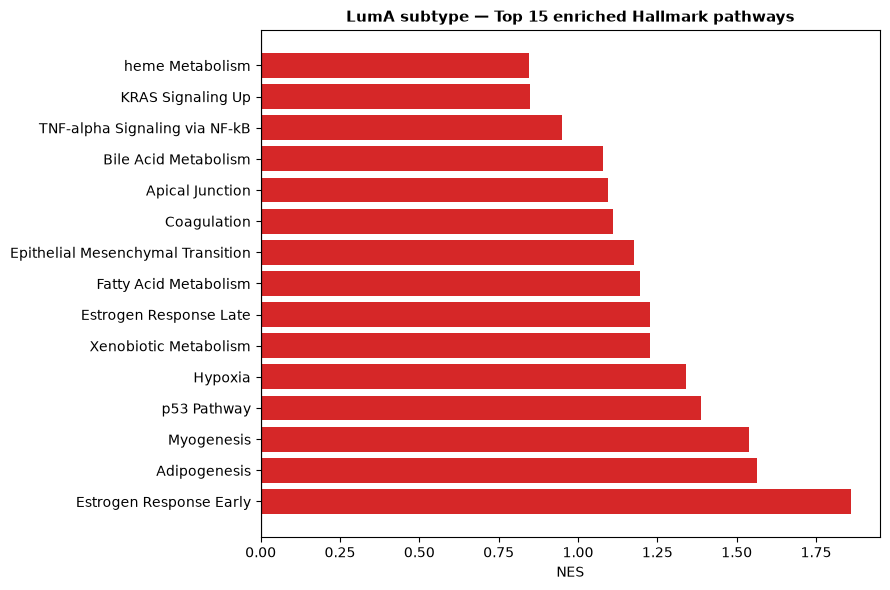

In [6]:
ranked_luma = build_ranked_list(
    de_results=de,
    subtype="LumA",
    gene_symbols=annotation,
)

try:
    gsea_luma = run_gsea_preranked(
        ranked=ranked_luma,
        gene_sets="MSigDB_Hallmark_2020",
    )
except Exception as exc:
    print(f"GSEA unavailable: {exc}")
    gsea_luma = pd.DataFrame(columns=["Term", "NES", "pval", "fdr"])

if not gsea_luma.empty and "NES" in gsea_luma.columns:
    top_luma = gsea_luma.nlargest(15, "NES")

    fig, ax = plt.subplots(figsize=(9, 6))
    colors = ["#d62728" if n > 0 else "#1f77b4" for n in top_luma["NES"]]
    ax.barh(top_luma["Term"], top_luma["NES"], color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("NES")
    ax.set_title("LumA subtype — Top 15 enriched Hallmark pathways", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("No GSEA results for LumA.")

## Basal vs LumA Enrichment Comparison

Expected biology: Basal tumours should be enriched for cell cycle / DNA damage / proliferation pathways (E2F targets, G2M checkpoint, MYC). LumA should be enriched for oestrogen signalling and fatty acid metabolism.

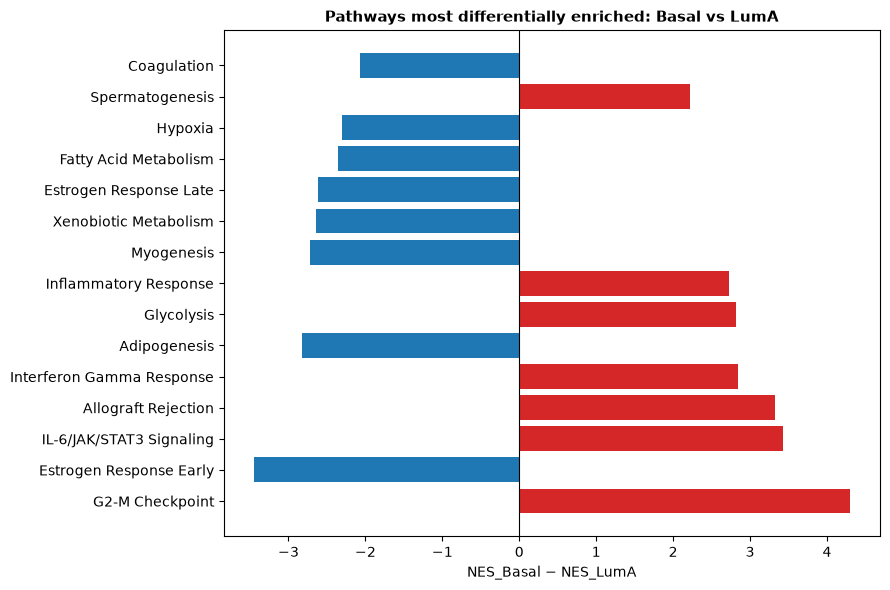

In [7]:
if not gsea_basal.empty and not gsea_luma.empty and "NES" in gsea_basal.columns:
    merged = gsea_basal[["Term", "NES"]].rename(columns={"NES": "NES_Basal"}).merge(
        gsea_luma[["Term", "NES"]].rename(columns={"NES": "NES_LumA"}),
        on="Term",
        how="inner",
    )
    merged["NES_diff"] = merged["NES_Basal"] - merged["NES_LumA"]
    top_diff = merged.reindex(merged["NES_diff"].abs().nlargest(15).index)

    fig, ax = plt.subplots(figsize=(9, 6))
    colors = ["#d62728" if d > 0 else "#1f77b4" for d in top_diff["NES_diff"]]
    ax.barh(top_diff["Term"], top_diff["NES_diff"], color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("NES_Basal − NES_LumA")
    ax.set_title("Pathways most differentially enriched: Basal vs LumA", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("Insufficient GSEA results for comparison.")